# AirCast: next-day air quality forecast for Chicago

**Track:** AI + Climate · **Team:** Parth Patel, Anay

**Who is this for?** A school athletics director (or a parent) in Chicago deciding
*today* whether tomorrow's outdoor practice should be moved indoors. Fine-particle
pollution (PM2.5) is the pollutant that matters most for that call: it penetrates
deep into the lungs, and children exercising outdoors are among the most exposed.

**What it does:** predicts tomorrow's average PM2.5 for Chicago from today's air
quality and weather, then turns the prediction into a concrete warning:
*"limit outdoor activity tomorrow"* when the forecast crosses the WHO daily
guideline (15 µg/m³).

**The rules we follow (from the brief):**
- One location (Chicago), one decision, one decider.
- Train on earlier dates, test on later dates — never shuffled.
- Every model is compared against the **persistence baseline**: "tomorrow will be
  the same as today." Beating it is the whole game in day-ahead forecasting.

## 1. Data

Both sources are from [Open-Meteo](https://open-meteo.com/) (free, no API key),
fetched by `src/fetch_data.py` and saved to `data/daily.csv`:

- **PM2.5**: hourly values from the CAMS atmospheric model, averaged to daily
  means. These are *model estimates (reanalysis)*, not physical monitor readings —
  the brief asks us to say this clearly, and we discuss what it means in the
  limitations section.
- **Weather**: daily temperature, precipitation, wind, humidity, radiation and
  pressure from Open-Meteo's historical weather archive.

Coverage: **2022-08-04 to 2025-11-12** (1,197 days, no gaps).

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# numpy's Accelerate BLAS on macOS raises spurious "divide by zero in matmul"
# RuntimeWarnings during Ridge regression. The outputs are correct - we assert
# every prediction is finite right after computing them (section 4).
warnings.filterwarnings("ignore", message=".*matmul.*", category=RuntimeWarning)

plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("data/daily.csv", parse_dates=["date"], index_col="date")
WHO_DAILY = 15.0   # WHO 2021 daily guideline, ug/m3
EPA_DAILY = 35.0   # US EPA 24-hour standard, ug/m3
df["pm25"].describe().round(1)

count    1197.0
mean       11.7
std         6.6
min         0.9
25%         7.2
50%        10.4
75%        14.5
max        57.4
Name: pm25, dtype: float64

### What three years of Chicago air looks like

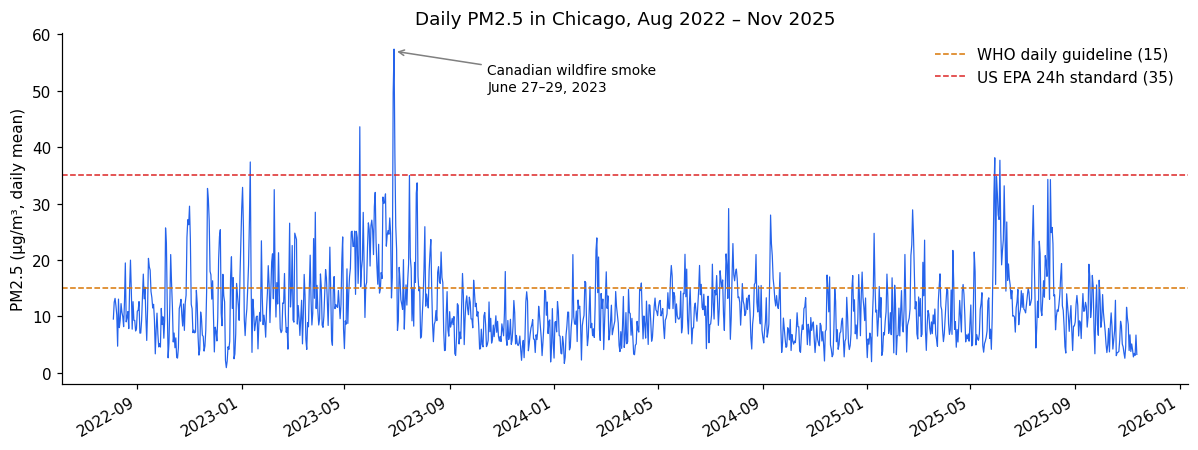

Days over WHO guideline (15): 269 of 1197 (22%)
Days over EPA standard (35):  7 of 1197


In [2]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(df.index, df["pm25"], lw=0.8, color="#2563eb")
ax.axhline(WHO_DAILY, color="#d97706", ls="--", lw=1, label=f"WHO daily guideline ({WHO_DAILY:.0f})")
ax.axhline(EPA_DAILY, color="#dc2626", ls="--", lw=1, label=f"US EPA 24h standard ({EPA_DAILY:.0f})")
ax.annotate("Canadian wildfire smoke\nJune 27–29, 2023", xy=(pd.Timestamp("2023-06-28"), 57),
            xytext=(pd.Timestamp("2023-10-15"), 50), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="gray"))
ax.set_ylabel("PM2.5 (µg/m³, daily mean)")
ax.set_title("Daily PM2.5 in Chicago, Aug 2022 – Nov 2025")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout(); fig.savefig("figures/01_history.png", bbox_inches="tight")
plt.show()

n = len(df)
print(f"Days over WHO guideline (15): {(df.pm25 > WHO_DAILY).sum()} of {n} ({(df.pm25 > WHO_DAILY).mean():.0%})")
print(f"Days over EPA standard (35):  {(df.pm25 > EPA_DAILY).sum()} of {n}")

Roughly **1 day in 5** exceeds the WHO guideline, so this is a real, recurring
decision — not a once-a-year event. The extreme days are wildfire smoke.

## 2. Features

To predict tomorrow, we only use information available **today**:

- today's PM2.5, yesterday's, the day before, and a 3-day average (recent trend)
- today's weather: wind (disperses particles), rain (washes them out), temperature,
  humidity, solar radiation, surface pressure (stagnant high-pressure days trap smog)
- the season, encoded as sine/cosine of day-of-year so December 31 sits next to January 1

The target is **tomorrow's daily-mean PM2.5** (`pm25` shifted back one day).

In [3]:
def build_features(d):
    f = pd.DataFrame(index=d.index)
    f["pm25_today"] = d["pm25"]
    f["pm25_lag1"] = d["pm25"].shift(1)
    f["pm25_lag2"] = d["pm25"].shift(2)
    f["pm25_3day_mean"] = d["pm25"].rolling(3).mean()
    for col in ["temperature_2m_mean", "temperature_2m_max", "precipitation_sum",
                "wind_speed_10m_max", "relative_humidity_2m_mean",
                "shortwave_radiation_sum", "surface_pressure_mean"]:
        f[col] = d[col]
    # wind direction is circular (359 deg is next to 0 deg), so encode as sin/cos
    wd = np.deg2rad(d["wind_direction_10m_dominant"])
    f["wind_dir_sin"], f["wind_dir_cos"] = np.sin(wd), np.cos(wd)
    doy = d.index.dayofyear / 365.25 * 2 * np.pi
    f["season_sin"], f["season_cos"] = np.sin(doy), np.cos(doy)
    return f

features = build_features(df)
target = df["pm25"].shift(-1).rename("pm25_tomorrow")
data = features.join(target).dropna()
print(f"{data.shape[0]} usable days, {features.shape[1]} features")
data.head(3).round(2)

1194 usable days, 15 features


,pm25_today,pm25_lag1,pm25_lag2,pm25_3day_mean,temperature_2m_mean,temperature_2m_max,precipitation_sum,wind_speed_10m_max,relative_humidity_2m_mean,shortwave_radiation_sum,surface_pressure_mean,wind_dir_sin,wind_dir_cos,season_sin,season_cos,pm25_tomorrow
date,,,,,,,,,,,,,,,,
2022-08-06,13.20,12.52,9.54,11.76,27.3,32.4,3.9,20.3,79,23.59,989.7,-0.14,-0.99,-0.57,-0.82,11.92
2022-08-07,11.92,13.20,12.52,12.55,25.4,29.1,47.4,20.9,89,7.30,988.9,-0.59,-0.81,-0.59,-0.81,10.27
2022-08-08,10.27,11.92,13.20,11.80,23.1,28.0,15.4,30.2,88,10.32,986.2,-0.96,0.29,-0.60,-0.80,4.74


## 3. Train/test split — by time, never shuffled

A random split would let the model "see the future" (days adjacent to test days),
which inflates scores dishonestly. We train on **Aug 2022 – Dec 2024** and test on
**all of 2025** — 316 days the model has never seen, including a 2025 wildfire-smoke
episode.

In [4]:
SPLIT = "2025-01-01"
train, test = data[data.index < SPLIT], data[data.index >= SPLIT]
X_train, y_train = train.drop(columns="pm25_tomorrow"), train["pm25_tomorrow"]
X_test, y_test = test.drop(columns="pm25_tomorrow"), test["pm25_tomorrow"]
print(f"Train: {len(train)} days ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test:  {len(test)} days ({test.index.min().date()} to {test.index.max().date()})")

Train: 879 days (2022-08-06 to 2024-12-31)
Test:  315 days (2025-01-01 to 2025-11-11)


## 4. Baseline and models

- **Persistence baseline:** tomorrow = today. Simple, and genuinely hard to beat.
- **Ridge regression** (linear regression with regularization, on scaled features).
- **Gradient-boosted trees** (`HistGradientBoostingRegressor`), in a default and a
  small/conservative version — with only ~900 training days, smaller trees can
  overfit less.

To choose between models **without peeking at the test year**, we use 5-fold
time-series cross-validation inside the training period: each fold trains on
earlier days and validates on the days right after them.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

candidates = {
    "Ridge regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Gradient-boosted trees (default)": HistGradientBoostingRegressor(random_state=0),
    "Gradient-boosted trees (small)": HistGradientBoostingRegressor(
        max_leaf_nodes=7, learning_rate=0.05, max_iter=300, random_state=0),
}
tscv = TimeSeriesSplit(n_splits=5)
cv_mae = {}
for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, cv=tscv,
                             scoring="neg_mean_absolute_error")
    cv_mae[name] = -scores.mean()
# persistence needs no training, so just score it on the same validation days
persist_cv = np.mean([mean_absolute_error(y_train.iloc[va], X_train["pm25_today"].iloc[va])
                      for _, va in tscv.split(X_train)])
cv_table = pd.Series({**cv_mae, "Persistence baseline": persist_cv},
                     name="CV MAE on training period (µg/m³)").sort_values().round(2)
cv_table

Ridge regression                    3.73
Persistence baseline                4.03
Gradient-boosted trees (default)    4.25
Gradient-boosted trees (small)      4.32
Name: CV MAE on training period (µg/m³), dtype: float64

The winner of cross-validation becomes **AirCast's model**. Only now do we touch
the 2025 test year — every model gets exactly one shot at it.

In [6]:
best_name = cv_table.drop("Persistence baseline").idxmin()
preds = {"Persistence (tomorrow = today)": X_test["pm25_today"]}
fitted = {}
for name, model in candidates.items():
    fitted[name] = model.fit(X_train, y_train)
    preds[name] = pd.Series(model.predict(X_test), index=X_test.index)

for name, p in preds.items():
    assert np.isfinite(p).all(), f"non-finite predictions from {name}"

results = pd.DataFrame({
    name: {"MAE (µg/m³)": mean_absolute_error(y_test, p),
           "RMSE (µg/m³)": root_mean_squared_error(y_test, p)}
    for name, p in preds.items()
}).T.round(2)
print(f"Model chosen by cross-validation: {best_name}")
results

Model chosen by cross-validation: Ridge regression


,MAE (µg/m³),RMSE (µg/m³)
Persistence (tomorrow = today),4.09,5.51
Ridge regression,3.70,4.94
Gradient-boosted trees (default),4.20,5.50
Gradient-boosted trees (small),3.90,5.24


### Test year: forecast vs. reality

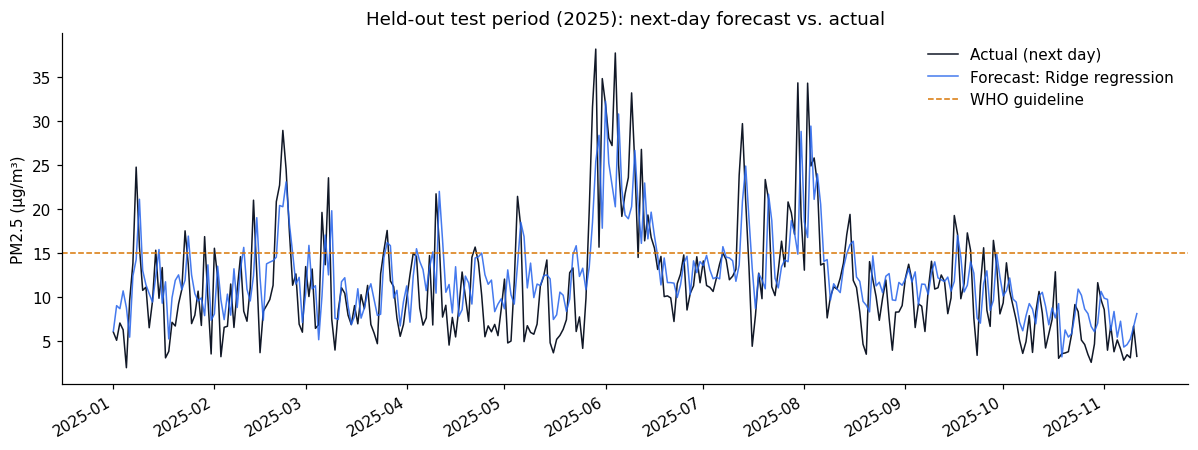

In [7]:
best = preds[best_name]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(y_test.index, y_test, lw=1, color="#111827", label="Actual (next day)")
ax.plot(best.index, best, lw=1, color="#2563eb", alpha=0.85, label=f"Forecast: {best_name}")
ax.axhline(WHO_DAILY, color="#d97706", ls="--", lw=1, label="WHO guideline")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Held-out test period (2025): next-day forecast vs. actual")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout(); fig.savefig("figures/02_test_forecast.png", bbox_inches="tight")
plt.show()

## 5. From forecast to decision: the outdoor-activity warning

The athletics director doesn't need a number — they need a yes/no by the end of
the school day. We issue a **warning** when predicted PM2.5 for tomorrow crosses
the WHO guideline (15 µg/m³), and score the warnings themselves:

- **Recall** — of the days that really were bad, how many did we warn about?
  (A missed warning means kids exercise outside in bad air.)
- **Precision** — of our warnings, how many were right?
  (Too many false alarms and people stop listening.)

There is a real trade-off here, and we resolve it the way weather services do —
with **two alert levels**:

- **WARNING** (act: move practice indoors): predicted PM2.5 above the WHO
  guideline itself. Tuned for precision — when it fires, it's usually right.
- **WATCH** (be ready: have an indoor backup plan): a more sensitive trigger that
  we tune on the **2024 validation year** — the lowest trigger that would have
  caught at least 85% of 2024's bad days. It fires more often and is sometimes
  wrong, but a watch costs little; a missed bad day (a child with asthma at
  outdoor practice in smoke) costs a lot.

The trigger is frozen on 2024 data *before* we score the 2025 test year.

In [8]:
from sklearn.metrics import precision_score, recall_score

def warning_scores(y_true, y_pred, trigger, threshold=WHO_DAILY):
    actual, warned = y_true > threshold, y_pred > trigger
    return {"Warnings issued": int(warned.sum()),
            "Bad days (actual)": int(actual.sum()),
            "Recall (bad days caught)": recall_score(actual, warned),
            "Precision (warnings correct)": precision_score(actual, warned)}

# Tune the trigger on 2024 only, with a model that never saw 2024
val_split = "2024-01-01"
v_train = data[data.index < val_split]
v_val = data[(data.index >= val_split) & (data.index < SPLIT)]
val_model = candidates[best_name].fit(v_train.drop(columns="pm25_tomorrow"), v_train["pm25_tomorrow"])
v_pred = pd.Series(val_model.predict(v_val.drop(columns="pm25_tomorrow")), index=v_val.index)
v_actual_bad = v_val["pm25_tomorrow"] > WHO_DAILY
trigger = WHO_DAILY
for t in np.arange(15.0, 8.0, -0.5):
    if recall_score(v_actual_bad, v_pred > t) >= 0.85:
        trigger = t
        break
print(f"WATCH trigger chosen on 2024 validation: predicted PM2.5 > {trigger} µg/m³")

# Refit on the full training period and score both alert levels on the 2025 test year
model = candidates[best_name].fit(X_train, y_train)
best = pd.Series(model.predict(X_test), index=X_test.index)
warning_table = pd.DataFrame({
    f"AirCast WATCH (trigger {trigger:g})": warning_scores(y_test, best, trigger),
    f"AirCast WARNING (trigger {WHO_DAILY:g})": warning_scores(y_test, best, WHO_DAILY),
    "Persistence (warn if today was bad)": warning_scores(y_test, X_test["pm25_today"], WHO_DAILY),
}).T
warning_table.round(2)

WATCH trigger chosen on 2024 validation: predicted PM2.5 > 11.5 µg/m³


,Warnings issued,Bad days (actual),Recall (bad days caught),Precision (warnings correct)
AirCast WATCH (trigger 11.5),167.0,65.0,0.89,0.35
AirCast WARNING (trigger 15),60.0,65.0,0.62,0.67
Persistence (warn if today was bad),65.0,65.0,0.60,0.60


Reading this honestly: the **WARNING** level is more precise than persistence
(fewer false alarms for the same kind of signal), while the **WATCH** level
catches far more of the genuinely bad days than either — at the cost of telling
the director to have a backup plan on days that turn out fine. That cost
asymmetry is exactly why real advisories use two levels.

## 6. Case study: would AirCast have warned before the June 2023 smoke crisis?

On June 27–28, 2023, wildfire smoke gave Chicago some of the worst air in the
world. This is exactly the day our user needs the tool to work — so we test it
honestly: we retrain the model using **only data available before June 2023**
and replay the event day by day.

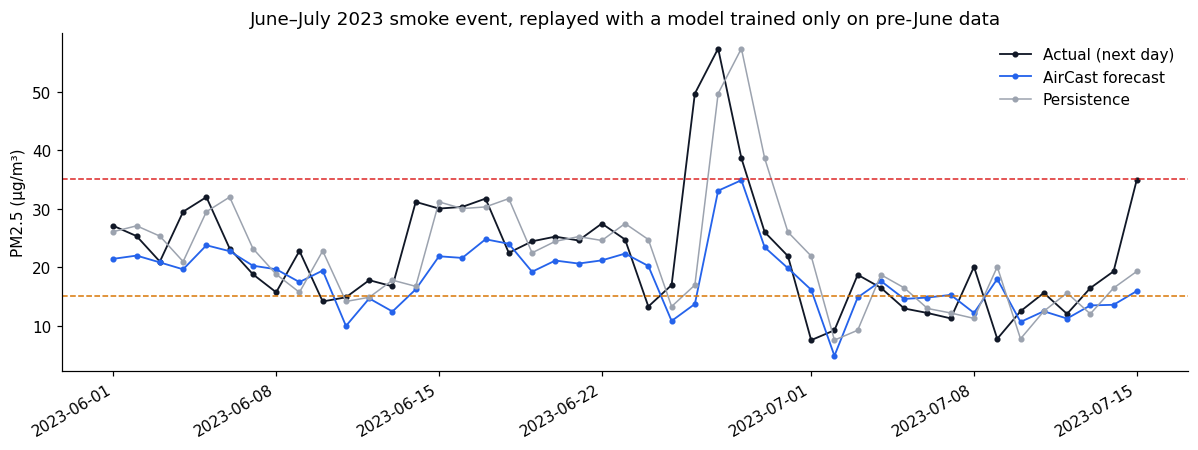

,actual_tomorrow,aircast,persistence,aircast_warns,persistence_warns
date,,,,,
2023-06-24,13.279167,20.2,24.7,True,True
2023-06-25,16.950000,10.8,13.3,False,False
2023-06-26,49.670833,13.7,17.0,False,True
2023-06-27,57.362500,33.1,49.7,True,True
2023-06-28,38.625000,34.9,57.4,True,True
2023-06-29,26.004167,23.4,38.6,True,True
2023-06-30,21.904167,19.8,26.0,True,True
2023-07-01,7.533333,16.1,21.9,True,True


In [9]:
from sklearn.base import clone

cs_train = data[data.index < "2023-06-01"]
cs_test = data[("2023-06-01" <= data.index) & (data.index <= "2023-07-15")]
cs_model = clone(candidates[best_name]).fit(
    cs_train.drop(columns="pm25_tomorrow"), cs_train["pm25_tomorrow"])
cs_pred = pd.Series(cs_model.predict(cs_test.drop(columns="pm25_tomorrow")), index=cs_test.index)
cs_persist = cs_test["pm25_today"]
cs_actual = cs_test["pm25_tomorrow"]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(cs_actual.index, cs_actual, "o-", ms=3, lw=1.2, color="#111827", label="Actual (next day)")
ax.plot(cs_pred.index, cs_pred, "o-", ms=3, lw=1.2, color="#2563eb", label="AirCast forecast")
ax.plot(cs_persist.index, cs_persist, "o-", ms=3, lw=1, color="#9ca3af", label="Persistence")
ax.axhline(WHO_DAILY, color="#d97706", ls="--", lw=1)
ax.axhline(EPA_DAILY, color="#dc2626", ls="--", lw=1)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("June–July 2023 smoke event, replayed with a model trained only on pre-June data")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout(); fig.savefig("figures/03_case_study.png", bbox_inches="tight")
plt.show()

event = pd.DataFrame({"actual_tomorrow": cs_actual, "aircast": cs_pred.round(1),
                      "persistence": cs_persist.round(1)}).loc["2023-06-24":"2023-07-01"]
event["aircast_warns"] = event["aircast"] > WHO_DAILY
event["persistence_warns"] = event["persistence"] > WHO_DAILY
event

## 7. How far ahead does the forecast stay useful?

We retrain the same model to predict 1, 2 and 3 days ahead and compare each
horizon against persistence at that horizon.

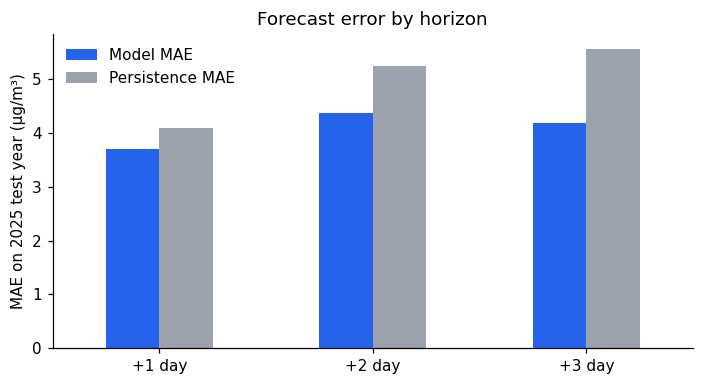

,Model MAE,Persistence MAE,Improvement
+1 day,3.70,4.09,10%
+2 day,4.37,5.25,17%
+3 day,4.19,5.56,25%


In [10]:
horizon_rows = {}
for h in [1, 2, 3]:
    tgt = df["pm25"].shift(-h)
    d_h = features.join(tgt.rename("y")).dropna()
    tr, te = d_h[d_h.index < SPLIT], d_h[d_h.index >= SPLIT]
    m = clone(candidates[best_name]).fit(tr.drop(columns="y"), tr["y"])
    horizon_rows[f"+{h} day"] = {
        "Model MAE": mean_absolute_error(te["y"], m.predict(te.drop(columns="y"))),
        "Persistence MAE": mean_absolute_error(te["y"], te["pm25_today"]),
    }
horizons = pd.DataFrame(horizon_rows).T.round(2)
horizons["Improvement"] = (1 - horizons["Model MAE"] / horizons["Persistence MAE"]).map("{:.0%}".format)

ax = horizons[["Model MAE", "Persistence MAE"]].plot.bar(
    rot=0, color=["#2563eb", "#9ca3af"], figsize=(6.5, 3.6))
ax.set_ylabel("MAE on 2025 test year (µg/m³)")
ax.set_title("Forecast error by horizon")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/04_horizons.png", bbox_inches="tight")
plt.show()
horizons

## 8. What drives tomorrow's air quality in Chicago?

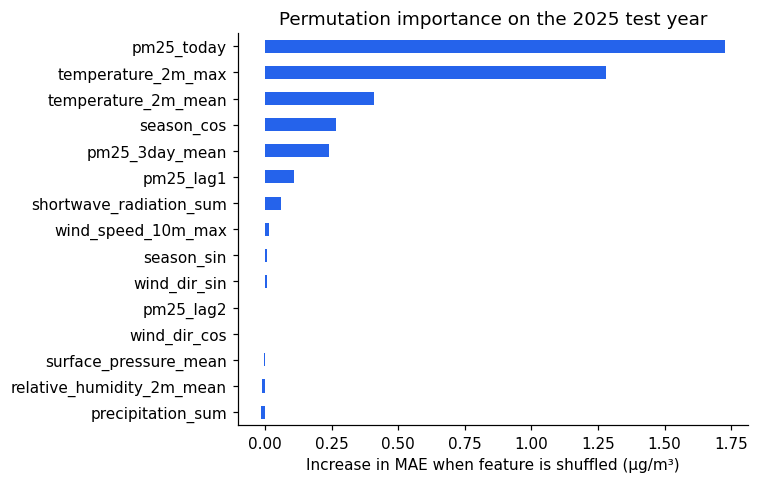

In [11]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=0,
                             scoring="neg_mean_absolute_error")
imp_series = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
imp_series.plot.barh(ax=ax, color="#2563eb")
ax.set_xlabel("Increase in MAE when feature is shuffled (µg/m³)")
ax.set_title("Permutation importance on the 2025 test year")
fig.tight_layout(); fig.savefig("figures/05_importance.png", bbox_inches="tight")
plt.show()

## 9. Where the model fails

In [12]:
errors = (best - y_test).rename("error")
worst = errors.abs().nlargest(8).index
fail = pd.DataFrame({"actual": y_test[worst], "forecast": best[worst].round(1),
                     "error": errors[worst].round(1)}).sort_values("error")
fail

,actual,forecast,error
date,,,
2025-07-30,34.283333,14.9,-19.4
2025-08-02,34.250000,16.8,-17.5
2025-06-04,37.670833,20.2,-17.4
2025-05-31,34.766667,17.8,-17.0
2025-05-28,31.541667,18.5,-13.1
2025-06-09,33.145833,20.3,-12.9
2025-05-29,38.112500,25.3,-12.8
2025-05-30,15.658333,28.3,12.7


## 10. Conclusions, honestly

In [13]:
p_mae = results.loc["Persistence (tomorrow = today)", "MAE (µg/m³)"]
m_mae = results.loc[best_name, "MAE (µg/m³)"]
watch, warn = warning_table.iloc[0], warning_table.iloc[1]
print(f"Chosen model: {best_name}")
print(f"Next-day MAE on 2025 test year: {m_mae} µg/m³ vs persistence {p_mae} µg/m³ "
      f"({1 - m_mae / p_mae:.0%} better)")
print(f"WATCH level:   caught {watch['Recall (bad days caught)']:.0%} of bad days "
      f"({watch['Precision (warnings correct)']:.0%} of watches correct)")
print(f"WARNING level: caught {warn['Recall (bad days caught)']:.0%} of bad days "
      f"({warn['Precision (warnings correct)']:.0%} of warnings correct)")

Chosen model: Ridge regression
Next-day MAE on 2025 test year: 3.7 µg/m³ vs persistence 4.09 µg/m³ (10% better)
WATCH level:   caught 89% of bad days (35% of watches correct)
WARNING level: caught 62% of bad days (67% of warnings correct)



**Where it fails, and why:**
- **Sudden smoke arrival.** When wildfire smoke rolls in overnight (June 27, 2023;
  May 30, 2025), nothing in today's local measurements predicts it. The model
  underestimates the first day of every major event, then catches up. A real
  deployment would add an upstream signal: satellite smoke plumes or PM2.5 from
  cities upwind.
- **Clean-up days.** After an event the model stays pessimistic for a day.

**Limitations we want judges to know about:**
- PM2.5 values are CAMS *model estimates*, not monitor readings (the brief's
  suggested fallback). The forecasting task is identical, but absolute levels can
  differ from EPA monitors; a deployed version would retrain on AirNow data.
- One city. The same pipeline runs for any location by changing three lines in
  `src/fetch_data.py` — but we make no claims beyond Chicago.
- This is a student prototype, not an official air-quality advisory.